In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

## Load and filter

In [2]:
df = pd.read_csv("skill_builder_data.csv", encoding="latin-1", low_memory=False)
print(df.shape)

df = df[df["original"] == 1]
print(df.shape)

print(df.columns.tolist())
print(df.head())

(525534, 30)
(449220, 30)
['order_id', 'assignment_id', 'user_id', 'assistment_id', 'problem_id', 'original', 'correct', 'attempt_count', 'ms_first_response', 'tutor_mode', 'answer_type', 'sequence_id', 'student_class_id', 'position', 'type', 'base_sequence_id', 'skill_id', 'skill_name', 'teacher_id', 'school_id', 'hint_count', 'hint_total', 'overlap_time', 'template_id', 'answer_id', 'answer_text', 'first_action', 'bottom_hint', 'opportunity', 'opportunity_original']
   order_id  assignment_id  user_id  assistment_id  problem_id  original  \
0  33022537         277618    64525          33139       51424         1   
1  33022709         277618    64525          33150       51435         1   
2  35450204         220674    70363          33159       51444         1   
3  35450295         220674    70363          33110       51395         1   
4  35450311         220674    70363          33196       51481         1   

   correct  attempt_count  ms_first_response tutor_mode  ... hint_coun

## Clean

In [3]:
df = df[["order_id","user_id","correct","attempt_count","hint_count","ms_first_response"]].dropna()
df = df[df["ms_first_response"] > 0]
df["rt_sec"] = df["ms_first_response"] / 1000
df["fast"] = (df["rt_sec"] < 2).astype(int)
df = df.sort_values(["user_id","order_id"]).reset_index(drop=True)
print(df.shape, df["user_id"].nunique(), "students")

(444536, 8) 4217 students


## Explore

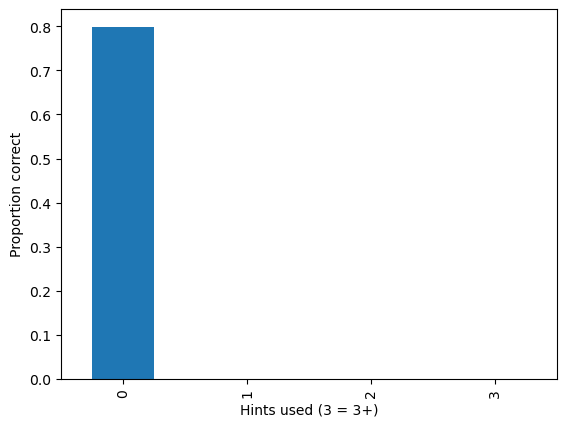

fast
0    0.696623
1    0.598917
Name: correct, dtype: float64
0.03821737722029262


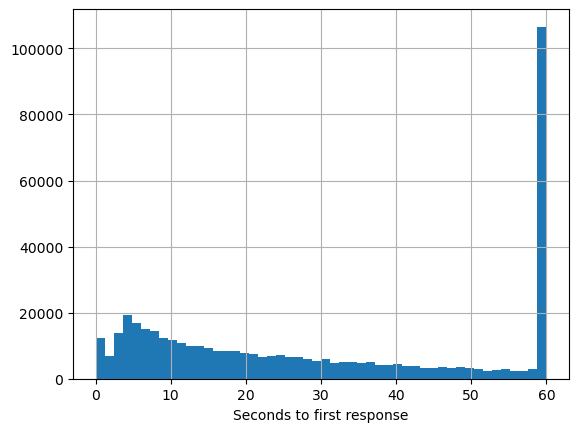

In [4]:
# Accuracy by number of hints used
df.groupby(df["hint_count"].clip(upper=3))["correct"].mean().plot(kind="bar")
plt.xlabel("Hints used (3 = 3+)"); plt.ylabel("Proportion correct")
plt.savefig("hints.png"); plt.show()

print(df.groupby("fast")["correct"].mean())
print(df["fast"].mean())   # share of responses that are fast

df["rt_sec"].clip(upper=60).hist(bins=50)
plt.xlabel("Seconds to first response")
plt.savefig("rt.png"); plt.show()

Note: in this dataset, `correct` means the student got the problem right on the first attempt without hints. So accuracy is near zero whenever a hint was used. This comes from how the label is defined, not from student behavior.

## Features

In [5]:
g = df.groupby("user_id")
df["prev_correct"]  = g["correct"].shift(1)
df["prev_hints"]    = g["hint_count"].shift(1)
df["prev_attempts"] = g["attempt_count"].shift(1)
df["prev_fast"]     = g["fast"].shift(1)
df["prev_log_rt"]   = np.log1p(g["rt_sec"].shift(1))
data = df.dropna(subset=["prev_correct"]).copy()
print(data.shape)

(440319, 13)


## Model

In [6]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

behavior = ["prev_correct","prev_hints","prev_attempts","prev_fast","prev_log_rt"]
baseline = ["prev_correct"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr, te = next(gss.split(data, groups=data["user_id"]))
train, test = data.iloc[tr], data.iloc[te]

for name, feats in [("Baseline", baseline), ("With behavior", behavior)]:
    m = LogisticRegression(max_iter=1000).fit(train[feats], train["correct"])
    p = m.predict_proba(test[feats])[:,1]
    print(name, "AUC =", round(roc_auc_score(test["correct"], p), 3))

m = LogisticRegression(max_iter=1000).fit(train[behavior], train["correct"])
print(dict(zip(behavior, m.coef_[0].round(3))))

Baseline AUC = 0.775
With behavior AUC = 0.779
{'prev_correct': 2.216, 'prev_hints': -0.184, 'prev_attempts': 0.008, 'prev_fast': 0.19, 'prev_log_rt': 0.104}


## Repeat splits

In [7]:
import numpy as np

res = []
for seed in range(5):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    tr, te = next(gss.split(data, groups=data["user_id"]))
    train, test = data.iloc[tr], data.iloc[te]
    out = []
    for feats in [baseline, behavior]:
        m = LogisticRegression(max_iter=1000).fit(train[feats], train["correct"])
        out.append(roc_auc_score(test["correct"], m.predict_proba(test[feats])[:, 1]))
    res.append(out)

res = np.array(res)
print("Mean AUC (baseline, behavior):", res.mean(axis=0).round(3))
print("Std across splits:", res.std(axis=0).round(3))
print("Gain per split:", (res[:, 1] - res[:, 0]).round(4))

Mean AUC (baseline, behavior): [0.765 0.773]
Std across splits: [0.011 0.014]
Gain per split: [ 0.0086  0.0081  0.0176 -0.0011  0.0095]
